In [74]:
import numpy as np
import matplotlib.pyplot as plt

def plot(overall_metrics, per_class_metrics):
    plt.figure(figsize=(7, 5))
    bars = plt.bar(overall_metrics.keys(), overall_metrics.values(), color=['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1'])

    # Annotate exact score on top of each bar
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

    plt.ylim(0, 1.1)
    plt.ylabel('Score')
    plt.title('Overall Summary Metrics')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    ###################################################
    num_classes = len(per_class_metrics['precision'])
    classes = [f'Class {i}' for i in range(num_classes)]

    x = np.arange(num_classes)
    width = 0.2  # Bar width

    plt.figure(figsize=(14, 6))

    for i, (metric, values) in enumerate(per_class_metrics.items()):
        plt.bar(x + i * width, values, width, label=metric)

    plt.xlabel('Classes')
    plt.ylabel('Score')
    plt.title('Per-Class Evaluation Metrics')
    plt.xticks(x + width * 1.5, classes)
    plt.ylim(0, 1.05)
    plt.legend(loc='lower right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

def plot_change(metrics, title, xlabel):
    num_classes = len(next(iter(metrics.values())))
    classes = [f'{xlabel} {i+1}' for i in range(num_classes)]

    x = np.arange(num_classes)

    all_values = np.concatenate([np.asarray(v) for v in metrics.values()])
    y_min, y_max = all_values.min(), all_values.max()

    padding = (y_max - y_min) * 0.1
    if padding == 0:
        padding = 0.01

    plt.figure(figsize=(14, 6))

    for metric, values in metrics.items():
        plt.plot(x, values, marker='o', linewidth=2, label=metric)

    plt.xlabel(xlabel+'s')
    plt.ylabel('Score')
    plt.title(title)
    plt.xticks(x, classes, rotation=30, ha='right')
    plt.ylim(y_min - padding, y_max + padding)
    plt.legend(loc='best')
    plt.grid(axis='both', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Results
# MultiPerceptronClassifier
---
## Model 1
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
|no.1| 6 min 37 sec |0.6971| 10 **parallel binary classifiers**, with **step activation** function |

| precision | recall | fscore |
|-|-|-|
| 0.7960 | 0.6971 | 0.7001 |

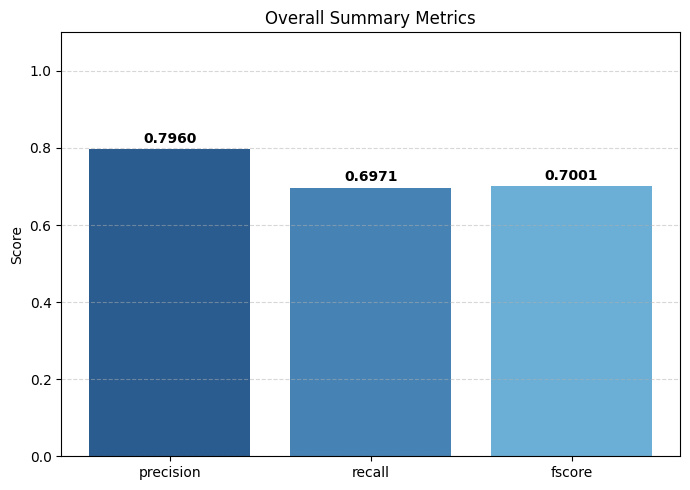

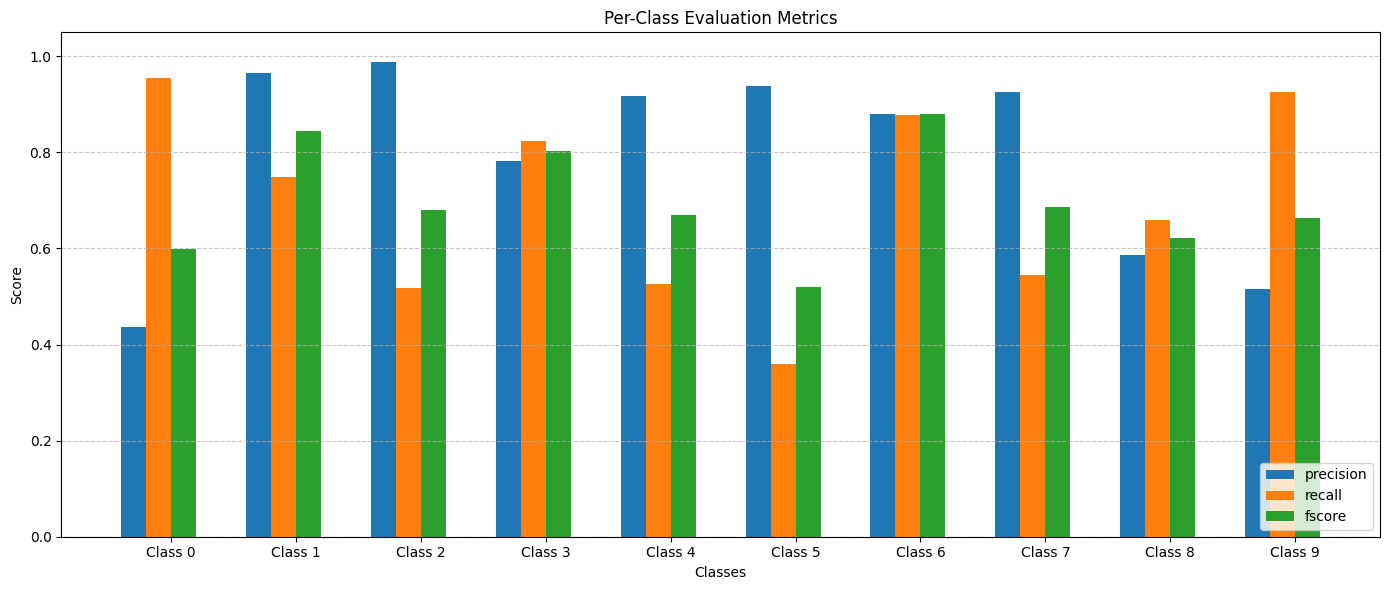

In [75]:
per_class_metrics = {'precision': [0.43650794, 0.96594779, 0.98890943, 0.7826905 , 0.91666667,
       0.93859649, 0.88075314, 0.92574257, 0.58614403, 0.51659292], 'recall': [0.95408163, 0.74977974, 0.51841085, 0.82376238, 0.52647658,
       0.35986547, 0.87891441, 0.54571984, 0.66016427, 0.92566898], 'fscore': [0.59897502, 0.84424603, 0.68022886, 0.8027014 , 0.66882277,
       0.52025932, 0.87983281, 0.68665851, 0.62095606, 0.66311679]}
overall_metrics = {'precision': 0.7960166598305259, 'recall': 0.6971, 'fscore': 0.700145545377378}
plot(overall_metrics, per_class_metrics)

## Model 2
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
|no.2|6 min 22 sec|0.8262| still independent classifiers, but with **argmax prediction** + **sigmoid activation** |

| precision | recall | fscore |
|-|-|-|
| 0.8519 | 0.8262 | 0.8247 |


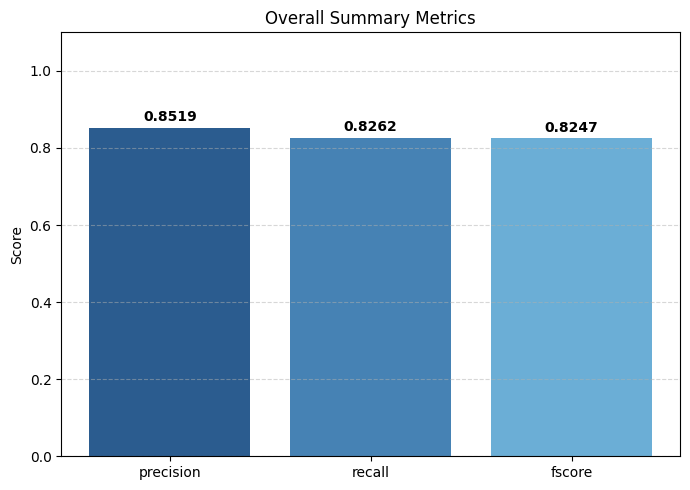

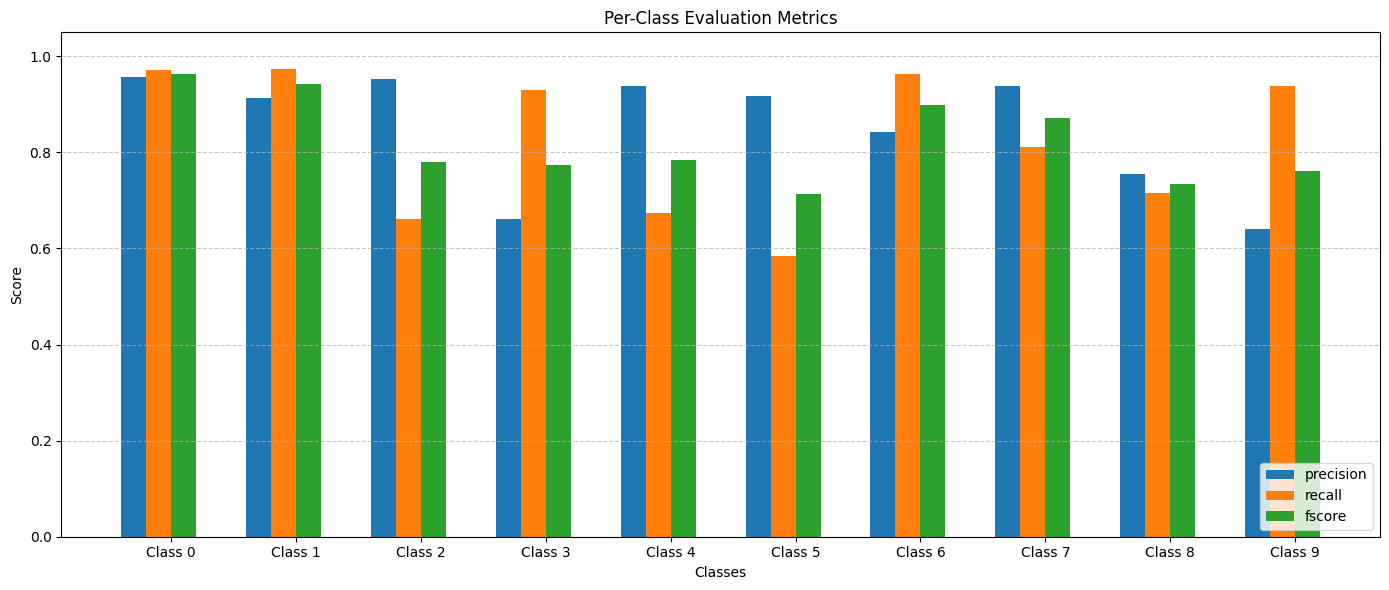

In [76]:
per_class_metrics = {'precision': [0.95678392, 0.91397849, 0.95251397, 0.66126761, 0.93758865,
       0.91725352, 0.84292237, 0.93925759, 0.754329  , 0.6402975 ], 'recall': [0.97142857, 0.97356828, 0.66085271, 0.92970297, 0.67311609,
       0.58408072, 0.96346555, 0.81225681, 0.71560575, 0.93855302], 'fscore': [0.96405063, 0.94283276, 0.78032037, 0.77283951, 0.7836396 ,
       0.71369863, 0.89917194, 0.87115284, 0.73445732, 0.76125402]}
overall_metrics = {'precision': 0.8518643791397928, 'recall': 0.8262, 'fscore': 0.8247315172316801}
plot(overall_metrics, per_class_metrics)

## Model 3
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
| no.3 | 5 min 22 sec | 0.8328 | **independent classifiers**, **argmax prediction**, **sigmoid activation**, **bce error function** |

| precision | recall | fscore |
|-|-|-|
| 0.8519 | 0.8328 | 0.8312 |

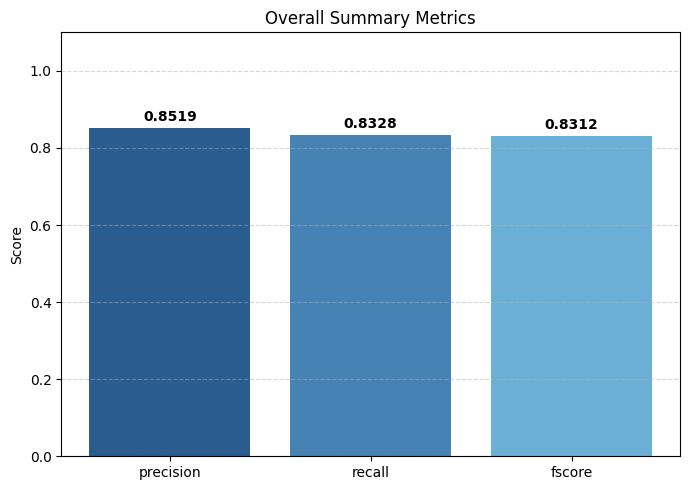

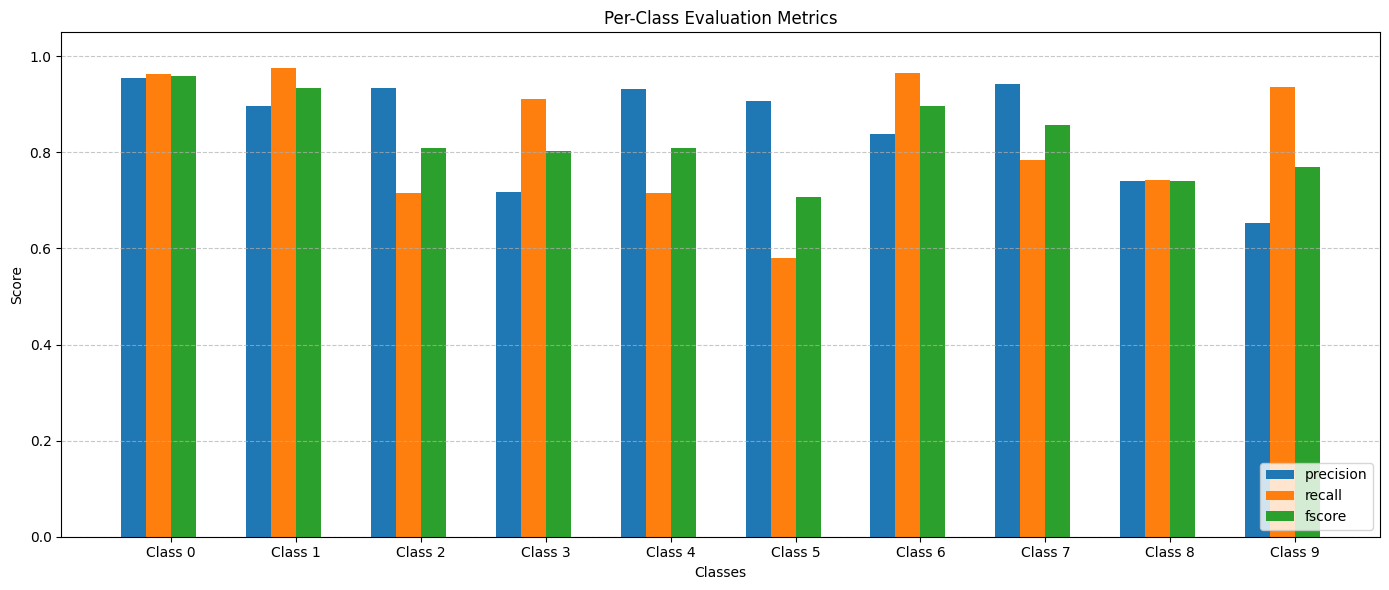

In [77]:
per_class_metrics = {'precision': [0.95449949, 0.89644013, 0.93417722, 0.71818891, 0.93103448,
       0.90718039, 0.83771532, 0.94269006, 0.74077869, 0.65397924], 'recall': [0.96326531, 0.97621145, 0.71511628, 0.91089109, 0.71486762,
       0.58071749, 0.96450939, 0.78404669, 0.74229979, 0.93657086], 'fscore': [0.95886237, 0.93462674, 0.81009879, 0.80314273, 0.80875576,
       0.70813397, 0.89665211, 0.85608072, 0.74153846, 0.77017115]}
overall_metrics = {'precision': 0.8518791660332464, 'recall': 0.8328, 'fscore': 0.8311941097197588}
plot(overall_metrics, per_class_metrics)

# MulticlassClassifier
---
|Attempt|Training time|Accuracy|Description|
|-|-|-|-|
| no.4 | - min - sec | 0.9022 | **Stohastic Gradient Descent** training, **softmax** activation, **Cross-entropy** log loss |

### 1 Epoch
| precision | recall | fscore |
|-|-|-|
| 0.8796 | 0.8745 | 0.8729 |

### 20 Epochs
| precision | recall | fscore |
|-|-|-|
| 0.9034 | 0.9022 | 0.9015 |

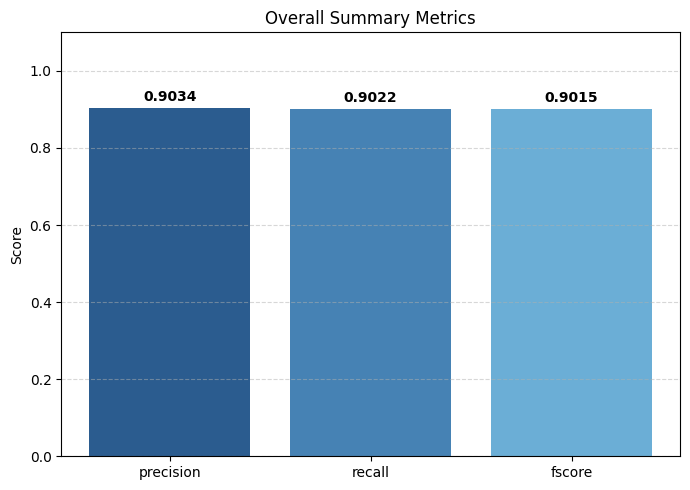

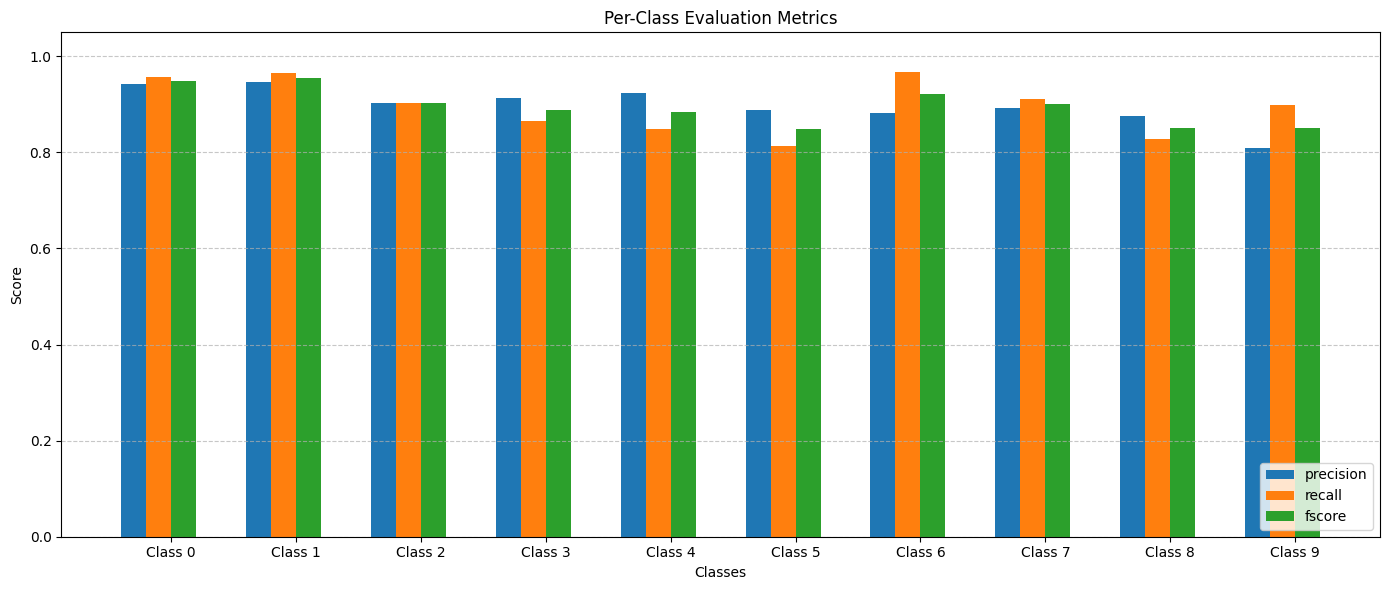

In [80]:
per_class_metrics = {'precision': [0.94265594, 0.94559585, 0.90310078, 0.91231733, 0.9245283 ,
       0.8873929 , 0.88106565, 0.89312977, 0.87608696, 0.80909902], 'recall': [0.95612245, 0.96475771, 0.90310078, 0.86534653, 0.84826884,
       0.81278027, 0.96659708, 0.91050584, 0.8275154 , 0.89890981], 'fscore': [0.94934144, 0.95508068, 0.90310078, 0.88821138, 0.88475836,
       0.84844939, 0.92185167, 0.9017341 , 0.85110876, 0.85164319]}
overall_metrics = {'precision': 0.9034, 'recall': 0.9022, 'fscore': 0.9015}
plot(overall_metrics, per_class_metrics)

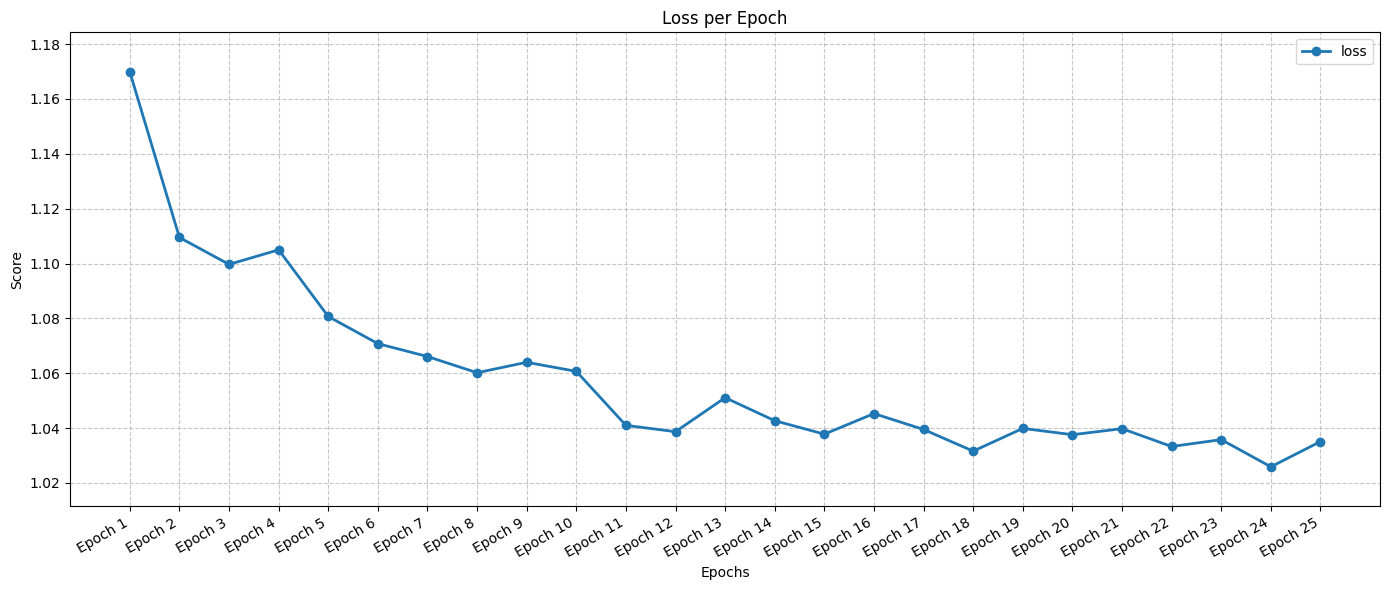

In [78]:
# Loss per Epoch
loss = {
    'loss': [1.1699, 1.1095, 1.0997, 1.1050, 1.0807, 1.0708, 1.0661, 1.0602, 1.0640, 1.0607, 1.0410, 1.0387, 1.0511, 1.0427, 1.0378, 1.0453, 1.0395, 1.0316, 1.0399, 1.0376, 1.0398, 1.0333, 1.0358, 1.0259, 1.0351]
}
plot_change(loss, 'Loss per Epoch', 'Epoch')

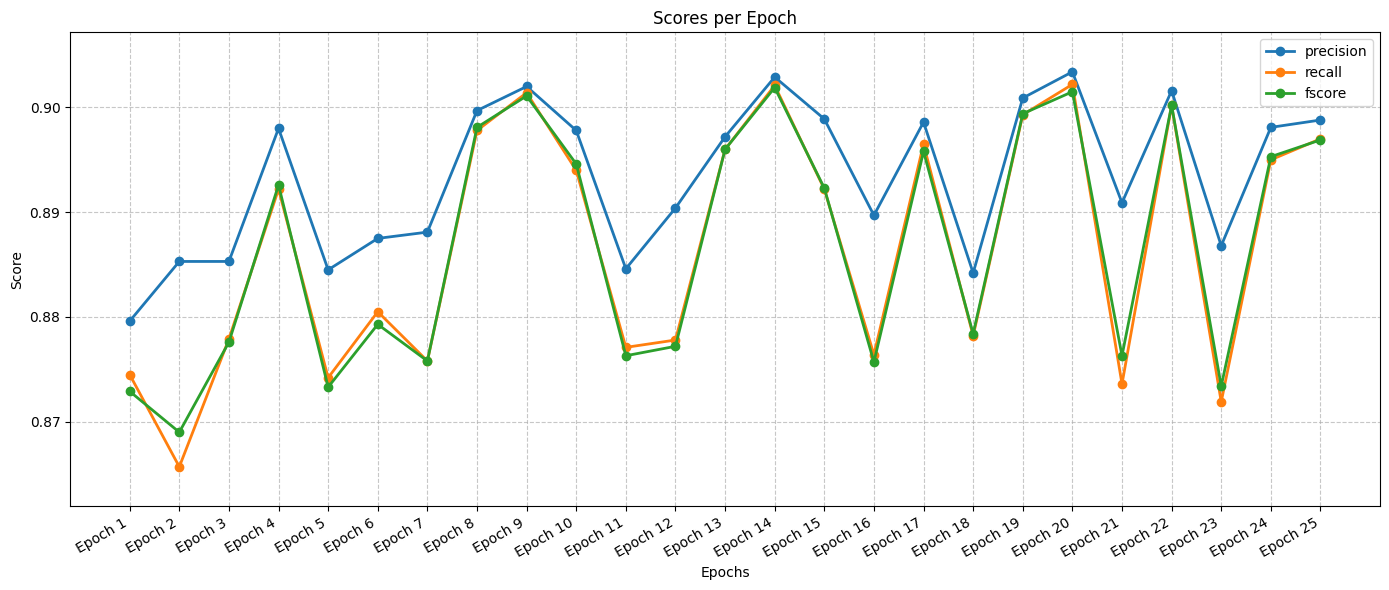

In [79]:
# Scores per epoch
stats_per_epoch = {
    'precision': [0.8796, 0.8853, 0.8853, 0.8980, 0.8845, 0.8875, 0.8881, 0.8997, 0.9020, 0.8978, 0.8846, 0.8904, 0.8972, 0.9029, 0.8989, 0.8897, 0.8986, 0.8842, 0.9009, 0.9034, 0.8909, 0.9016, 0.8868, 0.8981, 0.8988], 
    'recall':    [0.8745, 0.8657, 0.8779, 0.8922, 0.8742, 0.8805, 0.8758, 0.8978, 0.9014, 0.8940, 0.8771, 0.8778, 0.8960, 0.9021, 0.8922, 0.8764, 0.8965, 0.8782, 0.8993, 0.9022, 0.8736, 0.9002, 0.8719, 0.8950, 0.8970], 
    'fscore':    [0.8729, 0.8690, 0.8776, 0.8926, 0.8733, 0.8793, 0.8758, 0.8981, 0.9011, 0.8946, 0.8763, 0.8772, 0.8960, 0.9019, 0.8923, 0.8757, 0.8958, 0.8784, 0.8994, 0.9015, 0.8763, 0.9002, 0.8734, 0.8953, 0.8969]}
plot_change(stats_per_epoch, 'Scores per Epoch', 'Epoch')